# 03 — Khai phá luật kết hợp Agent theo bản đồ

Mục tiêu: tìm các Agent thường xuất hiện cùng nhau trong một đội hình 5 người, và kiểm tra (một cách thận trọng) tỷ lệ thắng của các tổ hợp.

Đơn vị phân tích: **một đội trong một ván**, tập 5 Agent không có thứ tự.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from valorant_mining.config import DATA_PROCESSED, VALID_MAPS
from valorant_mining.rules import mine_map_rules, run_rules
from valorant_mining.plotting import plot_rules, plot_composition_volume

comps = pd.read_csv(DATA_PROCESSED / "team_compositions.csv")
comps.groupby("Map").agg(teams=("GameID", "size"), labeled=("won", "count"))


,teams,labeled
Map,,
Ascent,6806,6652
Bind,5896,5730
Breeze,1176,1176
Fracture,198,198
Haven,6216,6036
Icebox,3494,3494
Split,4224,4096


## 1. Một bản đồ cụ thể: Ascent

In [2]:
rules_ascent, itemsets_ascent, baskets = mine_map_rules(comps, "Ascent", min_count=12)
rules_ascent[["rule", "support", "confidence", "lift", "support_count",
              "win_rate_with_antecedent", "map_baseline_win_rate"]].head(15)


,rule,support,confidence,lift,support_count,win_rate_with_antecedent,map_baseline_win_rate
240,"kayo → astra, jett",0.036438,0.714697,2.659503,248,0.527378,0.5
252,"kayo, killjoy → astra",0.030120,0.864979,2.641115,205,0.514768,0.5
239,"jett, kayo → astra",0.036438,0.813115,2.482754,248,0.527869,0.5
180,"killjoy, skye → astra",0.079929,0.800000,2.442710,544,0.510294,0.5
235,"kayo, sova → astra",0.038936,0.791045,2.415366,265,0.531343,0.5
48,kayo → astra,0.040112,0.786744,2.402233,273,0.527378,0.5
236,"kayo → astra, sova",0.038936,0.763689,2.398554,265,0.527378,0.5
154,"skye → astra, jett",0.091684,0.630940,2.347829,624,0.489383,0.5
145,"skye, sova → astra",0.098883,0.757030,2.311507,673,0.498313,0.5
153,"jett, skye → astra",0.091684,0.756364,2.309471,624,0.493333,0.5


## 2. Chạy cho tất cả bản đồ

In [3]:
result = run_rules(comps)
print(result["summary"])
display(result["report_rules"])


{'maps': ['Ascent', 'Bind', 'Breeze', 'Fracture', 'Haven', 'Icebox', 'Split'], 'teams': 28010, 'teams_with_win_label': 27382, 'rules': 580, 'maps_with_rules': 7, 'top_rule': 'kayo → astra, jett', 'top_lift': 3.730434782608696, 'exact_compositions_min8': 473}


,map,antecedent,consequent,rule,support,confidence,lift,support_count,n_teams,antecedent_len,consequent_len,n_with_antecedent,win_rate_with_antecedent,win_rate_ci_low,win_rate_ci_high,map_baseline_win_rate
0,Ascent,kayo,"astra, jett","kayo → astra, jett",0.036438,0.714697,2.659503,248,6806,1,2,347,0.527378,0.474835,0.579320,0.5
1,Ascent,"kayo, killjoy",astra,"kayo, killjoy → astra",0.030120,0.864979,2.641115,205,6806,2,1,237,0.514768,0.451411,0.577653,0.5
2,Ascent,"jett, kayo",astra,"jett, kayo → astra",0.036438,0.813115,2.482754,248,6806,2,1,305,0.527869,0.471843,0.583201,0.5
3,Ascent,"killjoy, skye",astra,"killjoy, skye → astra",0.079929,0.800000,2.442710,544,6806,2,1,680,0.510294,0.472769,0.547704,0.5
4,Ascent,"kayo, sova",astra,"kayo, sova → astra",0.038936,0.791045,2.415366,265,6806,2,1,335,0.531343,0.477853,0.584123,0.5
5,Ascent,kayo,astra,kayo → astra,0.040112,0.786744,2.402233,273,6806,1,1,347,0.527378,0.474835,0.579320,0.5
6,Bind,"brimstone, viper",skye,"brimstone, viper → skye",0.063433,0.785714,2.884540,374,5896,2,1,474,0.495781,0.450985,0.540645,0.5
7,Bind,"brimstone, skye",viper,"brimstone, skye → viper",0.063433,0.754032,2.768228,374,5896,2,1,496,0.508065,0.464174,0.551831,0.5
8,Bind,"jett, viper",astra,"jett, viper → astra",0.060380,0.704950,2.599367,356,5896,2,1,504,0.511905,0.468340,0.555290,0.5
9,Bind,"jett, skye",astra,"jett, skye → astra",0.071235,0.659341,2.431190,420,5896,2,1,637,0.510204,0.471438,0.548847,0.5


## 3. Đội hình 5 Agent và tỷ lệ thắng

Khoảng tin cậy Wilson 95% được tính cho từng đội hình. Đây là phân tích khám phá, chưa kiểm soát đội/patch và chưa hiệu chỉnh multiple comparisons.


In [4]:
comps_top = result["compositions"].sort_values("n", ascending=False).head(15)
comps_top[["map", "agents_str", "n", "win_rate", "win_rate_ci_low", "win_rate_ci_high"]]


,map,agents_str,n,win_rate,win_rate_ci_low,win_rate_ci_high
371,Icebox,jett|reyna|sage|sova|viper,896,0.465402,0.432958,0.498141
364,Icebox,jett|killjoy|sage|sova|viper,883,0.559456,0.526523,0.591874
304,Haven,cypher|jett|omen|phoenix|sova,617,0.489465,0.450208,0.528853
178,Bind,cypher|jett|omen|raze|sova,544,0.520221,0.478243,0.561914
15,Ascent,astra|jett|killjoy|skye|sova,462,0.543290,0.497697,0.588169
425,Split,breach|cypher|jett|omen|raze,428,0.485981,0.438965,0.533247
278,Haven,breach|cypher|jett|omen|sova,424,0.459906,0.413038,0.507493
218,Breeze,cypher|jett|skye|sova|viper,416,0.536058,0.488023,0.583432
309,Haven,cypher|jett|omen|reyna|sova,411,0.498783,0.450679,0.546910
65,Ascent,jett|killjoy|omen|reyna|sova,393,0.458015,0.409399,0.507444


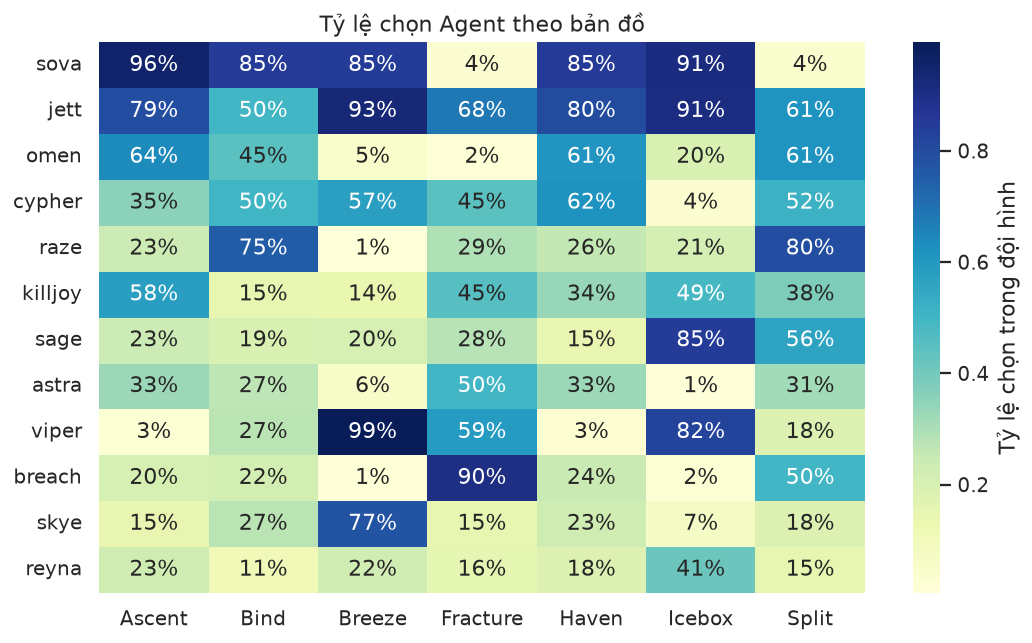

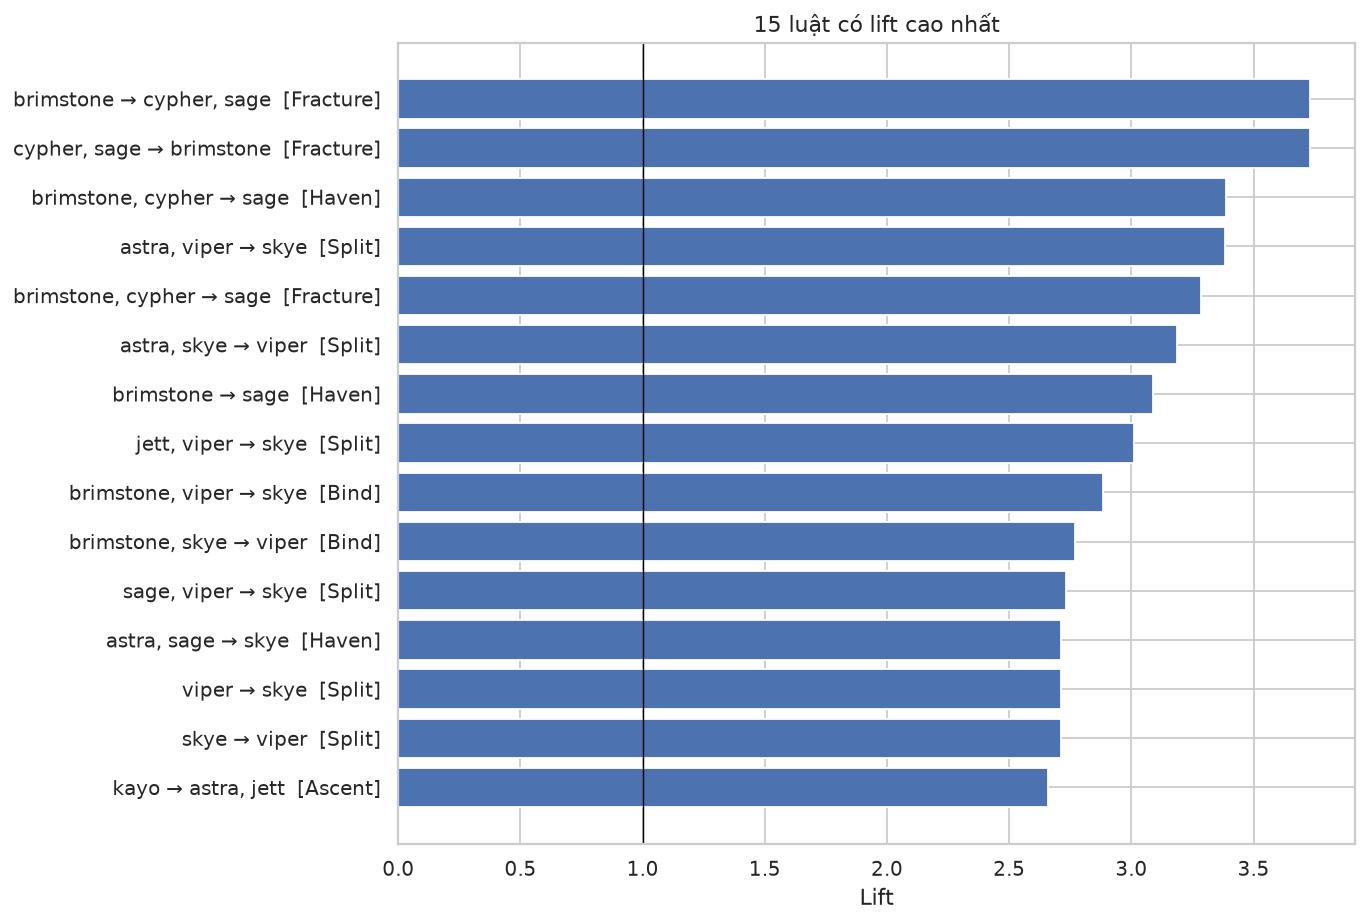

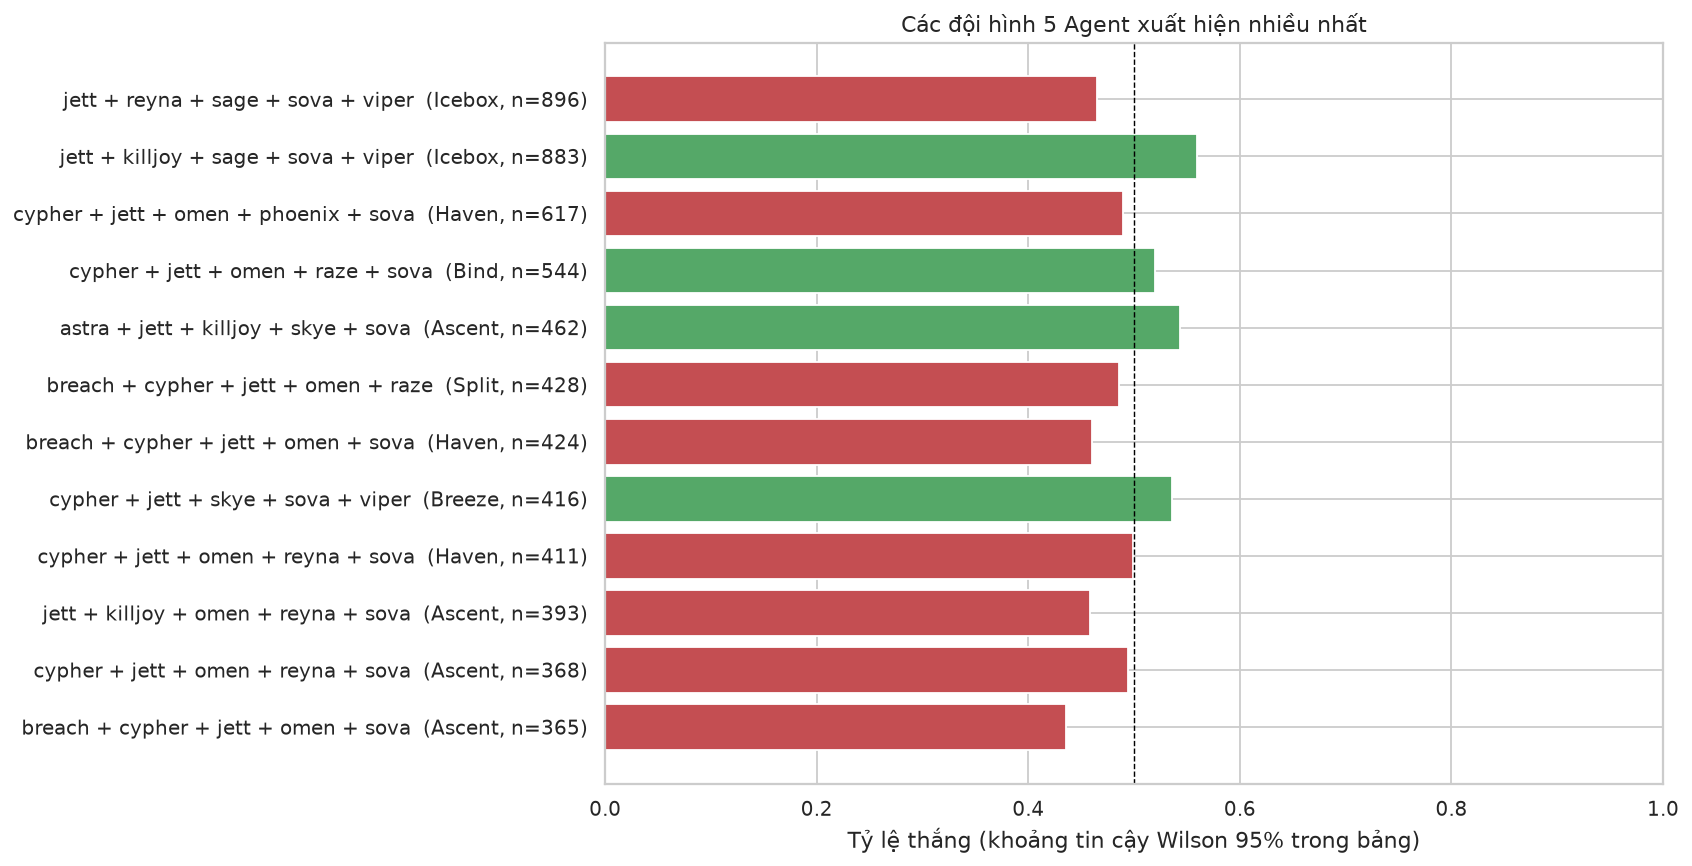

In [5]:
plot_rules(result)
plot_composition_volume(comps)
for name in ["03_agent_pickrate_map.png", "03_rules_top_lift.png", "03_compositions_winrate.png"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / name)))


## 4. Kết luận cần nhớ

- Mỗi map có một “meta” riêng: Icebox gần như cố định Viper–Sage–Sova; Bind thiên về Brimstone–Viper–Skye; Haven là Cypher–Omen–Sova.
- Support/confidence/lift đo **đồng xuất hiện**, không đo nhân quả.
- Phần lớn luật có win rate quanh 50%; các đội hình win rate cao thường có n nhỏ.
- Cần hold-out theo thời gian trước khi kết luận một tổ hợp “mạnh hơn”.
